
#### Feature engineering

Inputs: `clean.csv`, `returns.csv`, `stocks_clean.csv`, `macro.csv` (notebook 01)

Outputs: `data/processed/features.csv`, `feature_dictionary.csv`, figures `reports/figures/feat_*.png`

Goal: Create a set of meaningful numerical features that describe the market's condition each day. These features will help us group similar market conditions into regimes in the next stage.

converting raw financial data into meaningful indicators that describe whether the market is calm, volatile or under stress, while ensuring that no future information is used.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import sys; sys.path.insert(0, "..")
from src.common import PROC, TD, TRAIN_END, save_fig

sns.set_theme(style="whitegrid"); pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 90)
clean = pd.read_csv(PROC / "clean.csv", index_col="Date", parse_dates=True)
rets = pd.read_csv(PROC / "returns.csv", index_col="Date", parse_dates=True).reindex(clean.index)
stocks = pd.read_csv(PROC / "stocks_clean.csv", index_col="Date", parse_dates=True)
macro = pd.read_csv(PROC / "macro.csv", index_col="Date", parse_dates=True)
print(clean.shape, rets.shape, stocks.shape, macro.shape)

(4572, 11) (4572, 11) (4572, 15) (4572, 3)


#### 1. Building the Features

We created features that capture market direction, risk, fear, stock behaviour, global influences and RBI policy. Together, these features help describe the overall condition of the market on each day and identify different market regimes.

In [2]:
n = rets["nifty50"]
F, desc = pd.DataFrame(index=clean.index), {}
def add(name, series, text):
    F[name] = series; desc[name] = text

add("nifty_ret_5d", n.rolling(5).sum(), "Nifty 50 5-day log return")
add("nifty_ret_21d", n.rolling(21).sum(), "Nifty 50 21-day log return")
for w in (10, 21, 63):
    add(f"nifty_vol_{w}d", n.rolling(w).std() * np.sqrt(TD), f"Nifty 50 {w}-day realised volatility, annualised")
add("nifty_drawdown", clean["nifty50"] / clean["nifty50"].cummax() - 1, "Nifty 50 distance below its running peak")
for w in (21, 63):
    add(f"nifty_ma_gap_{w}d", np.log(clean["nifty50"] / clean["nifty50"].rolling(w).mean()), f"log of Nifty 50 over its {w}-day moving average")
add("nifty_skew_63d", n.rolling(63).skew(), "Skewness of Nifty 50 daily returns, 63 days")
add("nifty_kurt_63d", n.rolling(63).kurt(), "Excess kurtosis of Nifty 50 daily returns, 63 days")
add("vix_level", clean["india_vix"], "India VIX level")
add("vix_chg_5d", rets["india_vix"].rolling(5).sum(), "India VIX 5-day log change")
add("banknifty_rel_21d", rets["banknifty"].rolling(21).sum() - n.rolling(21).sum(), "Bank Nifty minus Nifty 50, 21-day log return")

sr = np.log(stocks).diff()
pair_corr = sr.rolling(63).corr()
iu = np.triu_indices(sr.shape[1], 1)
add("stock_corr_63d", pair_corr.groupby(level=0).apply(lambda m: m.values[iu].mean() if m.notna().all().all() else np.nan),
    "Average pairwise correlation of the 15 large stocks, 63 days")

G = pd.DataFrame(index=clean.index)
for c, label in [("usdinr", "USD/INR"), ("dxy", "Dollar index"), ("brent", "Brent crude"), ("gold", "Gold"), ("sp500", "S&P 500")]:
    G[f"{c}_ret_21d"] = rets[c].rolling(21).sum(); desc[f"{c}_ret_21d"] = f"{label} 21-day log return (shifted 1 day)"
G["us10y_chg_21d"] = clean["us10y"].diff(21); desc["us10y_chg_21d"] = "Change in the US 10-year yield over 21 days, percentage points (shifted 1 day)"
GLOBAL = list(G.columns)
F = F.join(G.shift(1))                                  # only what was known at the previous US close
add("repo_change_63d", macro["repo_rate"].diff(63), "Change in the RBI repo rate over 63 trading days, percentage points")

FEATURES = list(F.columns)
print(len(FEATURES), "features:", FEATURES)
print("Rows with any missing value (warm-up of the 63-day windows):", int(F.isna().any(axis=1).sum()))

21 features: ['nifty_ret_5d', 'nifty_ret_21d', 'nifty_vol_10d', 'nifty_vol_21d', 'nifty_vol_63d', 'nifty_drawdown', 'nifty_ma_gap_21d', 'nifty_ma_gap_63d', 'nifty_skew_63d', 'nifty_kurt_63d', 'vix_level', 'vix_chg_5d', 'banknifty_rel_21d', 'stock_corr_63d', 'usdinr_ret_21d', 'dxy_ret_21d', 'brent_ret_21d', 'gold_ret_21d', 'sp500_ret_21d', 'us10y_chg_21d', 'repo_change_63d']
Rows with any missing value (warm-up of the 63-day windows): 63


#### 2. Look-ahead checks
future-perturbation test, Shift test, Window test

These checks help ensure that our features do not contain future information, making the model's results more realistic and reliable.

In [3]:
def build_from(prices, rets_, stocks_, macro_):
    """Rebuild a few features from (possibly perturbed) inputs, with the same code path as above."""
    n_ = rets_["nifty50"]
    out = pd.DataFrame(index=prices.index)
    out["nifty_vol_21d"] = n_.rolling(21).std() * np.sqrt(TD)
    out["nifty_ma_gap_63d"] = np.log(prices["nifty50"] / prices["nifty50"].rolling(63).mean())
    out["sp500_ret_21d"] = rets_["sp500"].rolling(21).sum().shift(1)
    out["repo_change_63d"] = macro_["repo_rate"].diff(63)
    return out

cut = pd.Timestamp("2015-06-30")
pert = clean.copy(); pert.loc[pert.index > cut] *= np.random.default_rng(42).uniform(0.5, 1.5, size=pert.loc[pert.index > cut].shape)
base = build_from(clean, rets, stocks, macro)
moved = build_from(pert, np.log(pert).diff(), stocks, macro)
assert np.allclose(base.loc[:cut].dropna(), moved.loc[:cut].dropna()), "a feature uses data from after its date"
print("1. Future-perturbation test passed: features up to", cut.date(), "are unchanged when later prices are scrambled.")

G_unshifted = G
for t in pd.to_datetime(["2012-05-15", "2020-03-23", "2024-01-10"]):
    prev = clean.index[clean.index.get_loc(t) - 1]
    assert np.allclose(F.loc[t, GLOBAL].astype(float), G_unshifted.loc[prev, GLOBAL].astype(float))
print("2. Shift test passed: global features on day t equal the day t-1 values.")

import re
first = F.apply(lambda s: clean.index.get_loc(s.first_valid_index()))
window = {f: int(re.search(r"_(\d+)d", f).group(1)) if re.search(r"_(\d+)d", f) else 1 for f in FEATURES}
too_early = [f for f in FEATURES if first[f] < window[f] - 1]
assert not too_early, too_early
print("3. Window test passed. Earliest complete row:", F.dropna().index.min().date())

1. Future-perturbation test passed: features up to 2015-06-30 are unchanged when later prices are scrambled.
2. Shift test passed: global features on day t equal the day t-1 values.
3. Window test passed. Earliest complete row: 2008-06-09


#### 3. The final feature table

In [4]:
features = F.dropna().copy()
features["split"] = np.where(features.index <= TRAIN_END, "train", "test")
features.to_csv(PROC / "features.csv", index_label="Date")
dictionary = pd.DataFrame({"feature": FEATURES, "description": [desc[f] for f in FEATURES],
                           "group": ["global (shifted 1 day)" if f in GLOBAL else "macro (RBI)" if f.startswith("repo") else "Indian market" for f in FEATURES]})
dictionary.to_csv(PROC / "feature_dictionary.csv", index=False)
print("features.csv:", features.shape, features.index.min().date(), "to", features.index.max().date())
print(features["split"].value_counts().to_dict())
display(features[FEATURES].describe().T.round(3))

features.csv: (4509, 22) 2008-06-09 to 2026-10-27
{'train': 2336, 'test': 2173}


,count,mean,std,min,25%,50%,75%,max
nifty_ret_5d,4509.0,0.002,0.028,-0.213,-0.012,0.003,0.017,0.196
nifty_ret_21d,4509.0,0.007,0.060,-0.500,-0.020,0.010,0.039,0.303
nifty_vol_10d,4509.0,0.162,0.111,0.031,0.099,0.134,0.184,1.081
nifty_vol_21d,4509.0,0.166,0.105,0.051,0.107,0.140,0.184,0.895
nifty_vol_63d,4509.0,0.172,0.096,0.074,0.116,0.147,0.190,0.624
nifty_drawdown,4509.0,-0.079,0.088,-0.517,-0.109,-0.055,-0.018,0.000
nifty_ma_gap_21d,4509.0,0.003,0.033,-0.310,-0.013,0.006,0.021,0.194
nifty_ma_gap_63d,4509.0,0.010,0.059,-0.469,-0.016,0.015,0.042,0.327
nifty_skew_63d,4509.0,-0.087,0.645,-2.944,-0.378,-0.076,0.184,2.733
nifty_kurt_63d,4509.0,1.177,2.604,-1.135,-0.040,0.443,1.122,16.191


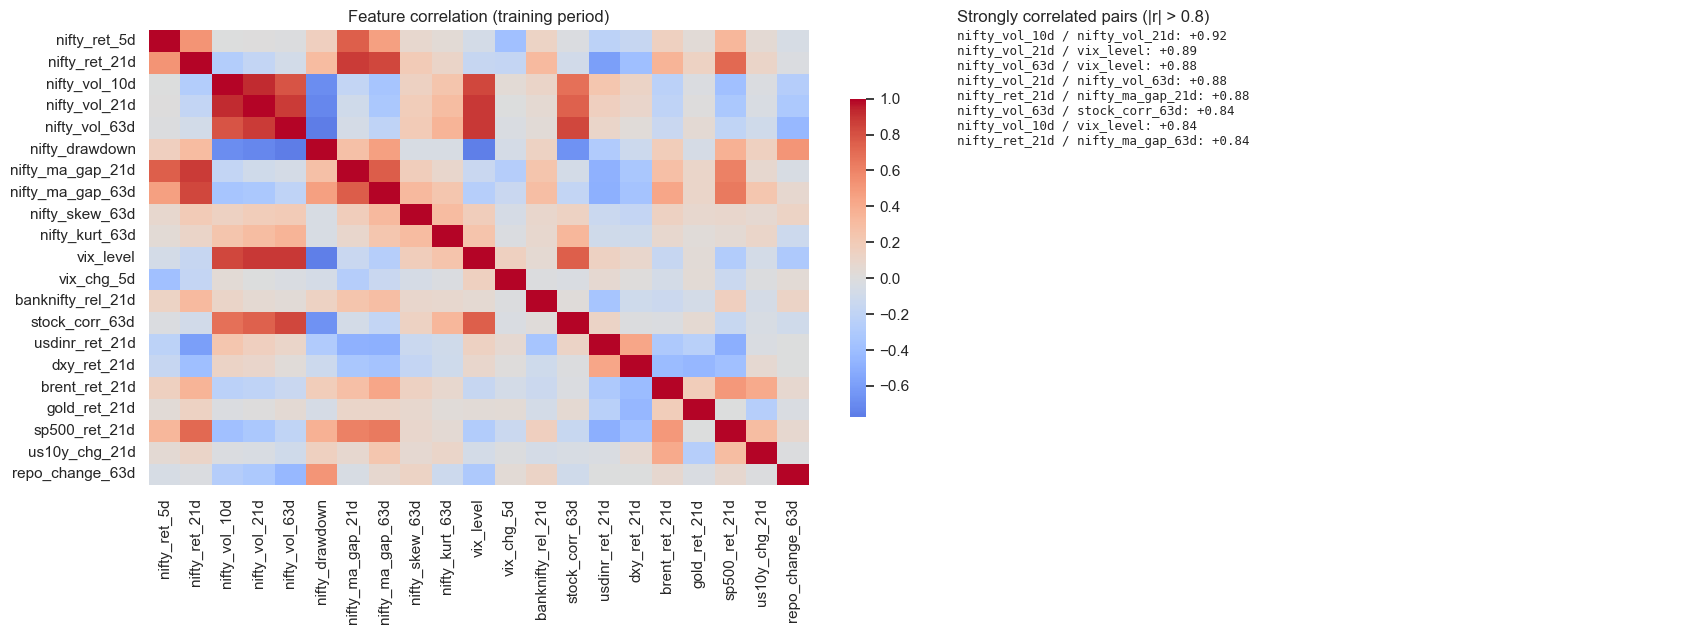

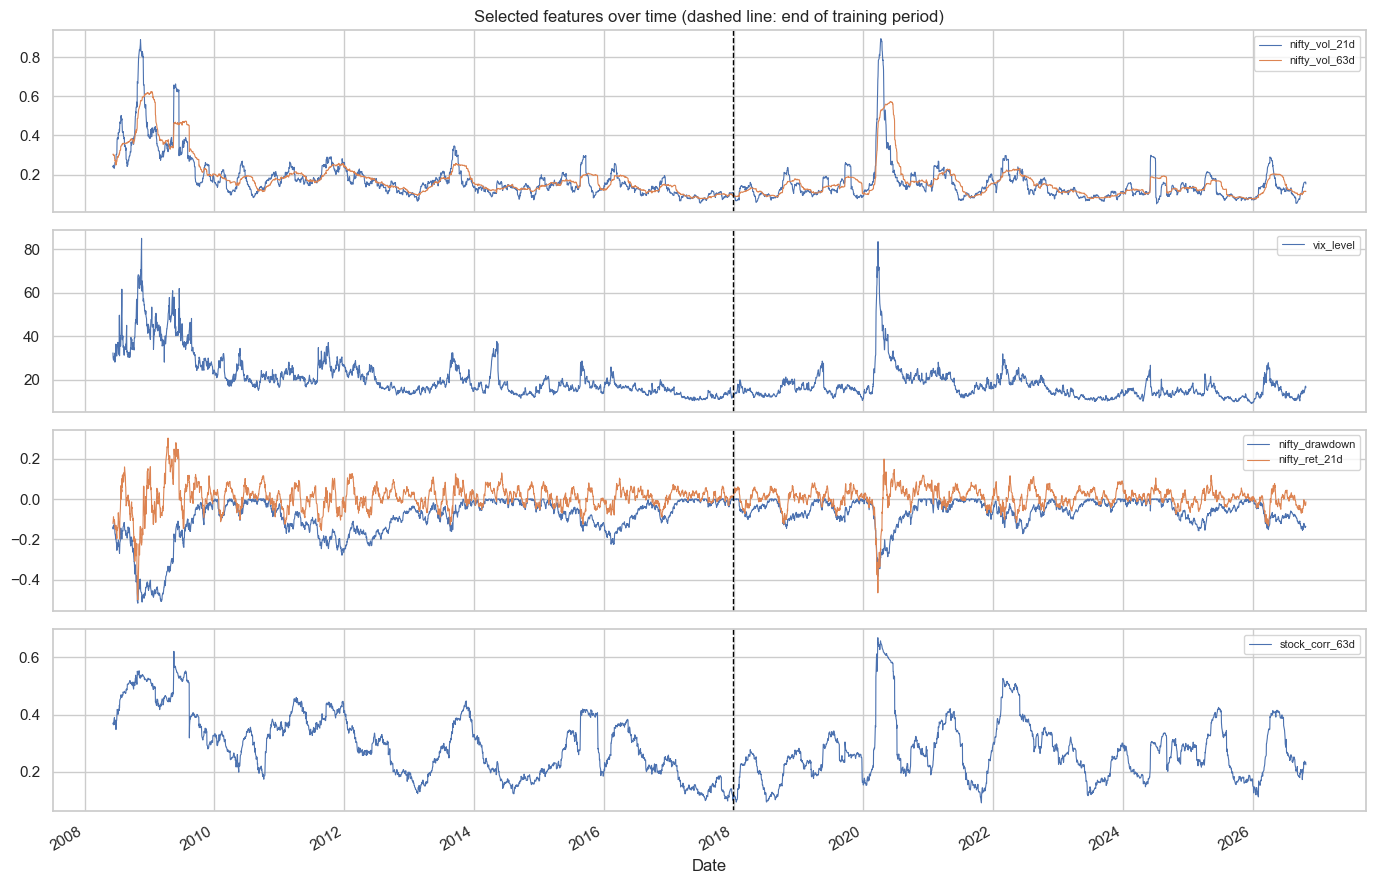

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(17, 6.5), gridspec_kw={"width_ratios": [1.15, 1]})
cm = features.loc[features["split"] == "train", FEATURES].corr()
sns.heatmap(cm, cmap="coolwarm", center=0, ax=ax[0], cbar_kws={"shrink": .7}); ax[0].set_title("Feature correlation (training period)")
strong = cm.where(np.triu(np.ones(cm.shape, bool), 1)).stack().loc[lambda s: s.abs() > .8].sort_values(key=abs, ascending=False)
ax[1].axis("off"); ax[1].set_title("Strongly correlated pairs (|r| > 0.8)", loc="left")
ax[1].text(0, 1, "\n".join(f"{a} / {b}: {v:+.2f}" for (a, b), v in strong.items()) or "none", va="top", family="monospace", fontsize=9)
save_fig(fig, "feat_correlation"); plt.show()

fig, axes = plt.subplots(4, 1, figsize=(14, 9), sharex=True)
for a, cols in zip(axes, [["nifty_vol_21d", "nifty_vol_63d"], ["vix_level"], ["nifty_drawdown", "nifty_ret_21d"], ["stock_corr_63d"]]):
    features[cols].plot(ax=a, lw=.8); a.axvline(TRAIN_END, color="black", ls="--", lw=1); a.legend(fontsize=8, loc="upper right")
axes[0].set_title("Selected features over time (dashed line: end of training period)")
save_fig(fig, "feat_timelines"); plt.show()

#### 4. Summary
1. 21 features created: We created 21 features across different groups to describe market behaviour. The complete dataset starts from 9 June 2008, after allowing 63 days for rolling calculations.

2. No future information used: All three look-ahead tests passed. Global market data is shifted by one day to ensure that only information available at the Indian market's closing time is used.

3. Some features deliberately excluded or modified:
- No 1-day return because daily movements can be noisy and cause regimes to change too frequently.
- US 10-year yield is represented by its 21-day change instead of its actual level because the level is non-stationary.

4. Some features are highly correlated: For example, different volatility windows and India VIX capture similar information. Similarly, returns and moving-average gaps overlap.